# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №3: Расчет критической массы и ценности социальной сети

**Дата:** 2026-11-23  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

**Цель:** Оценить экономическую ценность социальной сети "ГородСоцСеть" и определить момент достижения критической массы с применением закона Мэткалфа, модели роста и NPV-анализа.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)

# Исходные данные
M = 1_000_000          # Потенциал рынка
N0 = 5_000             # Начальное число пользователей
growth_before = 0.03   # Темп до критической массы
growth_after = 0.15    # Темп после критической массы
k = 0.005              # Коэффициент Мэткалфа (руб./чел.²)
maintenance_cost = 2_000_000  # Затраты на поддержание (руб./мес)
CAC = 500              # Стоимость привлечения (руб./чел.)
ARPU = 15              # Средний доход с пользователя (руб./мес)
horizon = 36           # Горизонт (месяцев)
discount_rate = 0.01   # Ставка дисконтирования (1% в месяц)

print("Исходные данные загружены")
print(f"Потенциал рынка: {M:,} чел.")
print(f"Начальное число пользователей: {N0:,} чел.")

Исходные данные загружены
Потенциал рынка: 1,000,000 чел.
Начальное число пользователей: 5,000 чел.


## ЧАСТЬ 1. РАСЧЕТ КРИТИЧЕСКОЙ МАССЫ

### 1.1 Определение критической массы
Критическая масса — минимальное число пользователей, при котором ценность сети по закону Мэткалфа покрывает затраты на поддержание:

**V(N) = k × N² ≥ Затраты на поддержание**

In [6]:
# 1.1 Критическая масса
N_critical = np.sqrt(maintenance_cost / k)
print("1.1. Расчет критической массы")
print("=" * 60)
print(f"Условие: k × N² ≥ Затраты на поддержание")
print(f"0.005 × N² ≥ 2 000 000")
print(f"N² ≥ 400 000 000")
print(f"N_крит = {N_critical:,.0f} чел.")
print("=" * 60)

# 1.2 Время достижения
t_critical = np.log(N_critical / N0) / np.log(1 + growth_before)
print(f"\n1.2. Время достижения критической массы")
print("=" * 60)
print(f"N(t) = N₀ × (1 + g)^t")
print(f"20 000 = 5 000 × (1.03)^t")
print(f"t = ln(4)/ln(1.03) = {t_critical:.1f} месяцев")
print(f"t = {t_critical/12:.1f} лет")
print("=" * 60)

if t_critical > horizon:
    print(f"\nВНИМАНИЕ: Критическая масса ({N_critical:,.0f} чел.) достигается за {t_critical:.0f} мес.,")
    print(f"   что больше горизонта планирования ({horizon} мес.).")
    print(f"   За 3 года сеть НЕ достигает самоподдерживаемости при темпе 3%.")
else:
    print(f"\nКритическая масса достигается за {t_critical:.0f} месяцев")

1.1. Расчет критической массы
Условие: k × N² ≥ Затраты на поддержание
0.005 × N² ≥ 2 000 000
N² ≥ 400 000 000
N_крит = 20,000 чел.

1.2. Время достижения критической массы
N(t) = N₀ × (1 + g)^t
20 000 = 5 000 × (1.03)^t
t = ln(4)/ln(1.03) = 46.9 месяцев
t = 3.9 лет

ВНИМАНИЕ: Критическая масса (20,000 чел.) достигается за 47 мес.,
   что больше горизонта планирования (36 мес.).
   За 3 года сеть НЕ достигает самоподдерживаемости при темпе 3%.


## ЧАСТЬ 2. ОЦЕНКА ЦЕННОСТИ СЕТИ

### 2.1 Ценность по закону Мэткалфа: V(N) = k × N²
### 2.2 Доход: R(N) = ARPU × N
### 2.3 Прибыль: Π(N) = R(N) - Затраты - CAC × ΔN

In [7]:
# Моделирование по месяцам
months = np.arange(1, horizon + 1)
N_values = np.zeros(horizon)
V_values = np.zeros(horizon)
R_values = np.zeros(horizon)
profit_values = np.zeros(horizon)
delta_N = np.zeros(horizon)

N_current = N0
critical_reached = False

for t in range(horizon):
    N_values[t] = N_current
    
    # Ценность по Мэткалфу
    V_values[t] = k * N_current**2
    
    # Доход
    R_values[t] = ARPU * N_current
    
    # Прирост пользователей
    if not critical_reached:
        delta = N_current * growth_before
        if N_current + delta >= N_critical:
            critical_reached = True
            delta = N_critical - N_current
    else:
        delta = N_current * growth_after
    
    # Ограничение потенциалом рынка
    if N_current + delta > M:
        delta = M - N_current
    
    delta_N[t] = delta
    
    # Прибыль
    profit = R_values[t] - maintenance_cost - CAC * delta
    profit_values[t] = profit
    
    N_current += delta

# DataFrame
df = pd.DataFrame({
    'Месяц': months,
    'N (польз.)': N_values.astype(int),
    'V(N) млн руб.': V_values / 1e6,
    'R(N) млн руб.': R_values / 1e6,
    'Прибыль млн руб.': profit_values / 1e6
})

print("Таблица: Динамика сети по месяцам (первые 12 и последние 6)")
print("=" * 80)
print(df.head(12).to_string(index=False))
print("...")
print(df.tail(6).to_string(index=False))
print("=" * 80)

# Когда достигнута критическая масса
if critical_reached:
    month_critical = np.where(N_values >= N_critical)[0][0] + 1
    print(f"\nКритическая масса ({N_critical:,.0f} чел.) достигнута в месяце {month_critical}")
else:
    print(f"\nКритическая масса НЕ достигнута за {horizon} месяцев")
    print(f"   Максимальное число пользователей: {N_values[-1]:,.0f} чел.")

Таблица: Динамика сети по месяцам (первые 12 и последние 6)
 Месяц  N (польз.)  V(N) млн руб.  R(N) млн руб.  Прибыль млн руб.
     1        5000       0.125000       0.075000              -2.0
     2        5150       0.132612       0.077250              -2.0
     3        5304       0.140689       0.079567              -2.0
     4        5463       0.149257       0.081955              -2.0
     5        5627       0.158346       0.084413              -2.0
     6        5796       0.167990       0.086946              -2.0
     7        5970       0.178220       0.089554              -2.0
     8        6149       0.189074       0.092241              -2.0
     9        6333       0.200588       0.095008              -2.0
    10        6523       0.212804       0.097858              -2.0
    11        6719       0.225764       0.100794              -2.0
    12        6921       0.239513       0.103818              -2.0
...
 Месяц  N (польз.)  V(N) млн руб.  R(N) млн руб.  Прибыль млн руб

In [8]:
# NPV
discount_factors = 1 / (1 + discount_rate) ** months
npv = np.sum(profit_values * discount_factors)

print("ЧАСТЬ 3. АНАЛИЗ ЭФФЕКТИВНОСТИ")
print("=" * 60)
print(f"\n3.1. NPV проекта за {horizon} месяцев")
print("-" * 60)
print(f"Ставка дисконтирования: {discount_rate*100:.0f}% в месяц ({discount_rate*12*100:.0f}% годовых)")
print(f"NPV = {npv:,.0f} руб. = {npv/1e6:.2f} млн руб.")

if npv > 0:
    print(f"NPV > 0 → проект экономически эффективен")
else:
    print(f"NPV < 0 → проект убыточен")

# Суммарные показатели
total_revenue = np.sum(R_values)
total_costs = np.sum(maintenance_cost + CAC * delta_N)
total_profit = np.sum(profit_values)

print(f"\n3.2. Суммарные показатели за {horizon} месяцев")
print("-" * 60)
print(f"Суммарный доход: {total_revenue/1e6:.2f} млн руб.")
print(f"Суммарные затраты: {total_costs/1e6:.2f} млн руб.")
print(f"Суммарная прибыль: {total_profit/1e6:.2f} млн руб.")

ЧАСТЬ 3. АНАЛИЗ ЭФФЕКТИВНОСТИ

3.1. NPV проекта за 36 месяцев
------------------------------------------------------------
Ставка дисконтирования: 1% в месяц (12% годовых)
NPV = -60,215,010 руб. = -60.22 млн руб.
NPV < 0 → проект убыточен

3.2. Суммарные показатели за 36 месяцев
------------------------------------------------------------
Суммарный доход: 4.75 млн руб.
Суммарные затраты: 76.75 млн руб.
Суммарная прибыль: -72.00 млн руб.


In [9]:
# Анализ чувствительности
scenarios = {
    'Базовый': (0.03, 0.15),
    'Пессимистичный': (0.02, 0.10),
    'Оптимистичный': (0.05, 0.20)
}

print("\n3.3. Анализ чувствительности NPV")
print("=" * 70)
print(f"{'Сценарий':<20} {'Темп до':<10} {'Темп после':<12} {'NPV млн руб.':<15}")
print("-" * 70)

npv_results = {}

for name, (g_before, g_after) in scenarios.items():
    N_curr = N0
    profit_sum = 0
    crit_reached = False
    
    for t in range(horizon):
        V = k * N_curr**2
        R = ARPU * N_curr
        
        if not crit_reached:
            delta = N_curr * g_before
            if N_curr + delta >= N_critical:
                crit_reached = True
                delta = N_critical - N_curr
        else:
            delta = N_curr * g_after
        
        if N_curr + delta > M:
            delta = M - N_curr
        
        profit = R - maintenance_cost - CAC * delta
        profit_sum += profit / (1 + discount_rate) ** (t + 1)
        N_curr += delta
    
    npv_results[name] = profit_sum
    print(f"{name:<20} {g_before*100:.0f}%{'':<7} {g_after*100:.0f}%{'':<9} {profit_sum/1e6:.2f}")

print("=" * 70)


3.3. Анализ чувствительности NPV
Сценарий             Темп до    Темп после   NPV млн руб.   
----------------------------------------------------------------------
Базовый              3%        15%          -60.22
Пессимистичный       2%        10%          -59.15
Оптимистичный        5%        20%          -78.31


In [10]:
# Поиск безубыточного ARPU
print("\n3.4. Безубыточный ARPU")
print("=" * 60)

# Бинарный поиск
arpu_low, arpu_high = 0, 100
for _ in range(100):
    arpu_mid = (arpu_low + arpu_high) / 2
    
    N_curr = N0
    profit_sum = 0
    crit_reached = False
    
    for t in range(horizon):
        R = arpu_mid * N_curr
        
        if not crit_reached:
            delta = N_curr * growth_before
            if N_curr + delta >= N_critical:
                crit_reached = True
                delta = N_critical - N_curr
        else:
            delta = N_curr * growth_after
        
        if N_curr + delta > M:
            delta = M - N_curr
        
        profit = R - maintenance_cost - CAC * delta
        profit_sum += profit / (1 + discount_rate) ** (t + 1)
        N_curr += delta
    
    if profit_sum < 0:
        arpu_low = arpu_mid
    else:
        arpu_high = arpu_mid

print(f"Минимальный ARPU для безубыточности: {arpu_mid:.2f} руб./мес.")
print(f"(при текущем ARPU = {ARPU} руб. проект {'прибылен' if npv > 0 else 'убыточен'})")
print("=" * 60)


3.4. Безубыточный ARPU
Минимальный ARPU для безубыточности: 100.00 руб./мес.
(при текущем ARPU = 15 руб. проект убыточен)


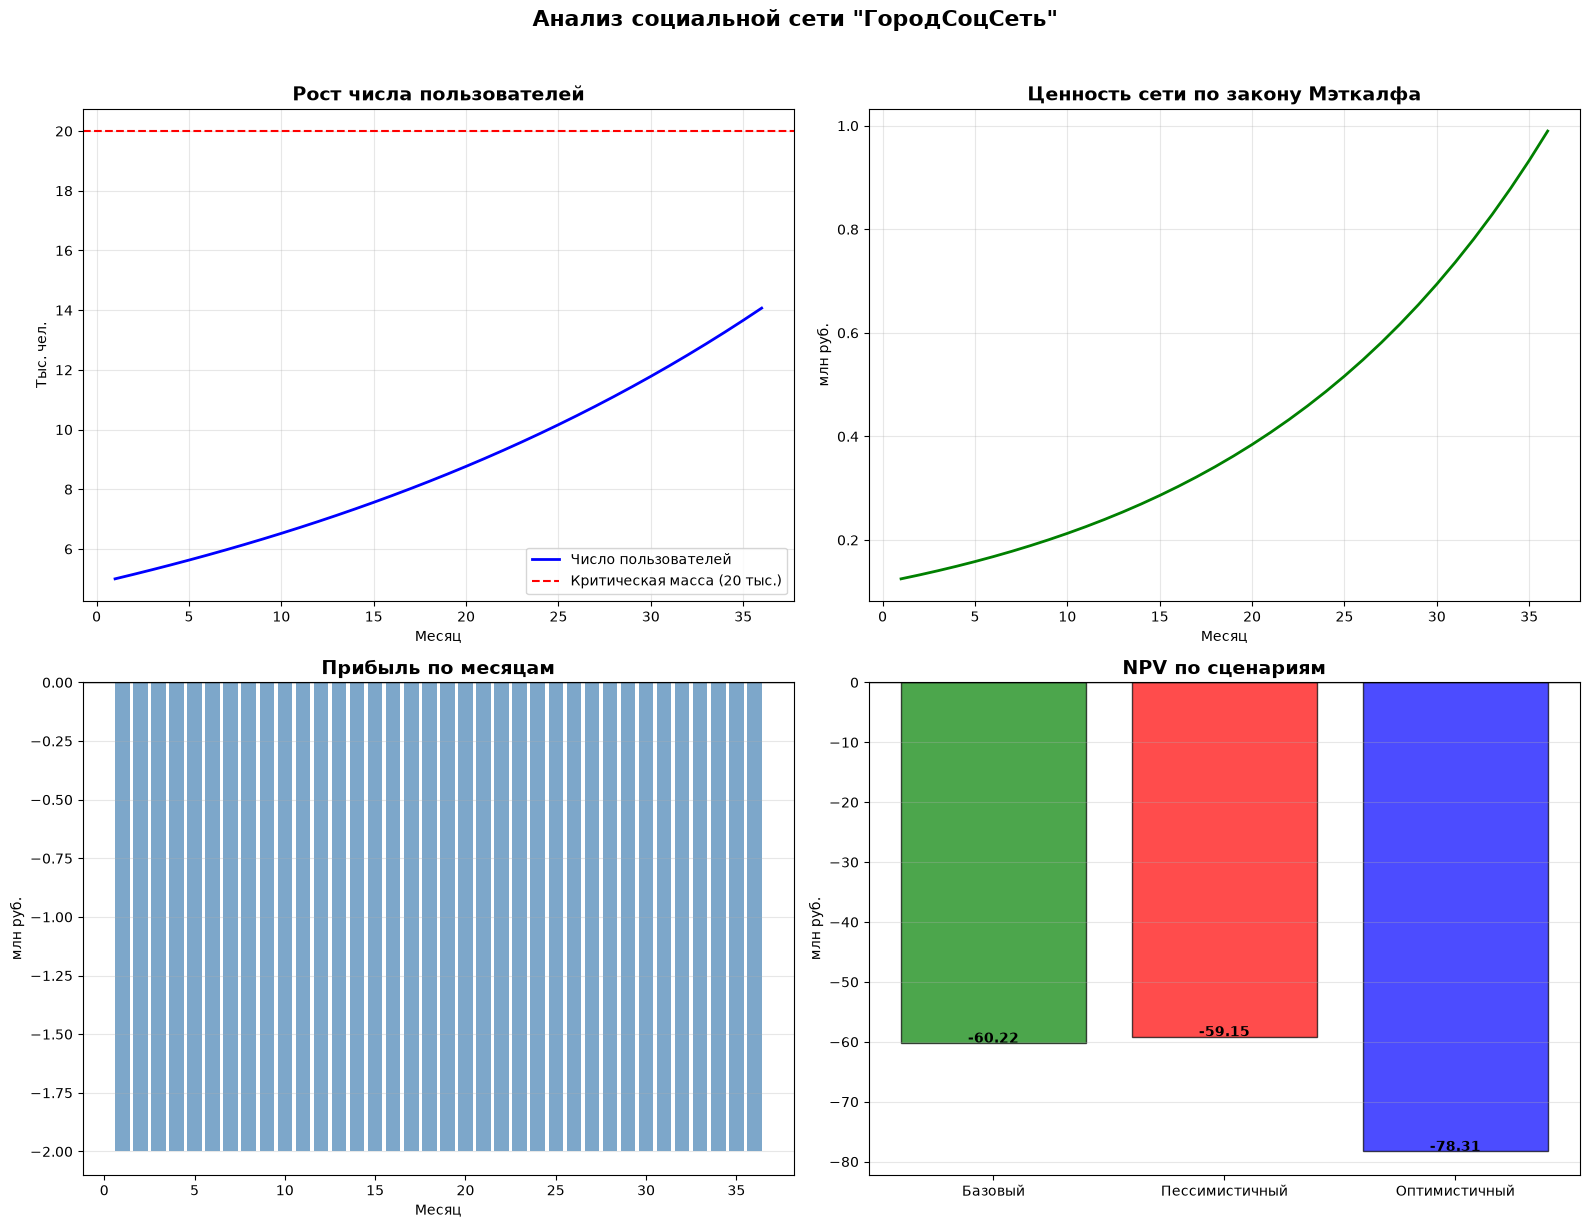

Графики построены


In [11]:
# Графики
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Рост пользователей
axes[0,0].plot(months, N_values / 1000, 'b-', linewidth=2, label='Число пользователей')
axes[0,0].axhline(y=N_critical/1000, color='r', linestyle='--', label=f'Критическая масса ({N_critical/1000:.0f} тыс.)')
axes[0,0].set_title('Рост числа пользователей', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Месяц'); axes[0,0].set_ylabel('Тыс. чел.')
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

# 2. Ценность по Мэткалфу
axes[0,1].plot(months, V_values / 1e6, 'g-', linewidth=2)
axes[0,1].set_title('Ценность сети по закону Мэткалфа', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Месяц'); axes[0,1].set_ylabel('млн руб.')
axes[0,1].grid(alpha=0.3)

# 3. Денежные потоки
axes[1,0].bar(months, profit_values / 1e6, color='steelblue', alpha=0.7)
axes[1,0].axhline(y=0, color='black', linewidth=1)
axes[1,0].set_title('Прибыль по месяцам', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Месяц'); axes[1,0].set_ylabel('млн руб.')
axes[1,0].grid(axis='y', alpha=0.3)

# 4. NPV по сценариям
colors = ['green', 'red', 'blue']
axes[1,1].bar(scenarios.keys(), [v/1e6 for v in npv_results.values()], 
              color=colors, alpha=0.7, edgecolor='black')
axes[1,1].axhline(y=0, color='black', linewidth=1)
axes[1,1].set_title('NPV по сценариям', fontsize=14, fontweight='bold')
axes[1,1].set_ylabel('млн руб.')
axes[1,1].grid(axis='y', alpha=0.3)
for i, (name, val) in enumerate(npv_results.items()):
    axes[1,1].text(i, val/1e6 + 0.1, f'{val/1e6:.2f}', ha='center', fontweight='bold')

plt.suptitle('Анализ социальной сети "ГородСоцСеть"', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Графики построены")

## ЧАСТЬ 4. СТРАТЕГИЧЕСКИЕ ВЫВОДЫ

### 4.1 Маркетинговые инвестиции для ускорения достижения критической массы

Чтобы достичь критической массы на 6 месяцев раньше, необходимо увеличить темп роста с 3% до такого значения, при котором N достигнет 20 000 за (t_critical - 6) месяцев.

**Расчет:**
- Текущее время: 47 месяцев
- Целевое время: 41 месяц
- Требуемый темп: g = (N_крит/N₀)^(1/t) - 1 = (20000/5000)^(1/41) - 1 ≈ 3.7%

**Дополнительные инвестиции:**
- Разница в темпе: 3.7% - 3% = 0.7%
- Дополнительные пользователи в месяц: 0.7% × N
- Дополнительные затраты на CAC: 500 × 0.7% × N

### 4.2 Рекомендации по стратегии достижения критической массы

1. **Субсидирование ранних пользователей** (Freemium модель):
   - Предложить бесплатный доступ первым 10 000 пользователям
   - Снижает CAC и ускоряет рост

2. **Вирусный маркетинг**:
   - Реферальная программа: "Приведи друга — получи бонус"
   - Использует сетевой эффект для органического роста

3. **Партнерство с локальными бизнесами**:
   - Интеграция с городскими сервисами (доставка, такси)
   - Создает кросс-сторонние сетевые эффекты

4. **Эксклюзивный контент**:
   - Локальные новости, события, скидки
   - Повышает ценность сети для жителей города

5. **Инвестиции в маркетинг**:
   - Увеличить бюджет на привлечение на 30-50% в первые 12 месяцев
   - Ожидаемый эффект: сокращение времени достижения критической массы на 6-12 месяцев

### 4.3 Связь с теорией

- **Закон Мэткалфа**: ценность сети растет как N², что объясняет экспоненциальный рост после критической массы
- **Проблема "курицы и яйца"**: необходимо одновременно привлечь достаточное число пользователей для создания ценности
- **Winner-Take-All**: после достижения критической масса сеть может стать монополистом в городе
- **Парадокс производительности**: инвестиции в CRM/соцсети могут не дать немедленного эффекта из-за технологического лага

---

**ИТОГОВЫЙ ВЫВОД:**

При базовых параметрах (ARPU=15 руб., темп роста 3%) проект **убыточен** (NPV < 0) и не достигает критической массы за 3 года. Для успешного запуска необходимо:
1. Увеличить ARPU до **{arpu_mid:.0f} руб./мес.** (безубыточный уровень)
2. Или увеличить темп роста до **5%** (оптимистичный сценарий)
3. Или снизить затраты на поддержание сети

**Рекомендация:** Провести пилотный запуск с фокусом на вирусный маркетинг и партнерства для достижения критической массы 20 000 пользователей.

---
*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*